In [2]:
!pip uninstall -y torchvision torchaudio
!pip uninstall -y bitsandbytes triton
!pip install -q bitsandbytes==0.45.3
!pip install -q transformers==4.51.0 accelerate==0.34.0 peft==0.11.1 trl==0.9.4 sentencepiece==0.2.0

Found existing installation: bitsandbytes 0.45.3
Uninstalling bitsandbytes-0.45.3:
  Successfully uninstalled bitsandbytes-0.45.3
Found existing installation: triton 3.6.0
Uninstalling triton-3.6.0:
  Successfully uninstalled triton-3.6.0


In [3]:
import bitsandbytes as bnb
print(f"BNB version: {bnb.__version__}")

# Check GPU support correctly
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"GPU: {torch.cuda.get_device_name(0)}")

# Check if bnb can see CUDA
try:
    import bitsandbytes.functional as F
    print("✅ BNB functional import OK — GPU support working")
except Exception as e:
    print(f"❌ BNB error: {e}")

BNB version: 0.45.3
CUDA available: True
GPU: Tesla T4
✅ BNB functional import OK — GPU support working


In [4]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

model_name = "md-nishat-008/TigerLLM-1B-it"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    trust_remote_code=True,
    use_fast=False
)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map={"": 0},
    trust_remote_code=True
)
model.config.use_cache = False

print("✅ Base model ready")
print(f"✅ Device : {next(model.parameters()).device}")
print(f"✅ Params : {sum(p.numel() for p in model.parameters()):,}")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

chat_template.jinja: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

2026-06-08 02:25:08.688239: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1780885508.883857      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1780885508.938249      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1780885509.394369      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780885509.394408      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1780885509.394411      58 computation_placer.cc:177] computation placer alr

model.safetensors:   0%|          | 0.00/2.00G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/197 [00:00<?, ?B/s]

✅ Base model ready
✅ Device : cuda:0
✅ Params : 651,005,056


In [5]:
import torch
import transformers, trl, peft

print(f"Transformers : {transformers.__version__}")
print(f"TRL          : {trl.__version__}")
print(f"PEFT         : {peft.__version__}")
print(f"Torch        : {torch.__version__}")
print(f"GPU          : {torch.cuda.get_device_name(0)}")

Transformers : 4.51.0
TRL          : 0.9.4
PEFT         : 0.11.1
Torch        : 2.10.0+cu128
GPU          : Tesla T4


In [6]:
# CELL 1 — Imports
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
import json
import nltk
from transformers import TrainingArguments
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel
from trl import SFTTrainer
from datasets import load_dataset

nltk.download('punkt')
print("✅ All imports done")
print(f"✅ GPU available: {torch.cuda.is_available()}")
print(f"✅ GPU name: {torch.cuda.get_device_name(0)}")

✅ All imports done
✅ GPU available: True
✅ GPU name: Tesla T4


[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [7]:
def ask(mdl, tok, question, max_new_tokens=256):
    prompt = f"""<bos><start_of_turn>system
আপনি একজন বাংলা চিকিৎসা সহকারী। নিচের প্রশ্নের বিস্তারিত উত্তর দিন।<end_of_turn>
<start_of_turn>user
{question}<end_of_turn>
<start_of_turn>model
"""
    inputs = tok(prompt, return_tensors="pt").to("cuda")
    with torch.no_grad():
        outputs = mdl.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            temperature=0.7,
            do_sample=True,
            pad_token_id=tok.eos_token_id,
            eos_token_id=tok.eos_token_id
        )
    generated = outputs[0][inputs["input_ids"].shape[1]:]
    return tok.decode(generated, skip_special_tokens=True)

# Fixed test questions for before/after comparison
test_questions = [
    "ডায়াবেটিসের প্রধান লক্ষণগুলো কী কী?",
    "উচ্চ রক্তচাপ কমানোর উপায় কী?",
]

print("=" * 60)
print("BASE MODEL OUTPUTS (before fine-tuning)")
print("=" * 60)

base_outputs = {}
for q in test_questions:
    print(f"\n❓ {q}")
    ans = ask(model, tokenizer, q)
    print(f"💬 {ans}")
    base_outputs[q] = ans
    print("-" * 60)

with open("/kaggle/working/base_model_outputs.json", "w", encoding="utf-8") as f:
    json.dump(base_outputs, f, ensure_ascii=False, indent=2)

print("\n✅ Base outputs saved!")

BASE MODEL OUTPUTS (before fine-tuning)

❓ ডায়াবেটিসের প্রধান লক্ষণগুলো কী কী?
💬 ডায়াবেটিস (Diabetes) একটি রোগ যা শরীরের রক্তে শর্করার মাত্রা বেড়ে যায়, যা সাধারণত ইনসুলিন দ্বারা নিয়ন্ত্রণে রাখা হয়। ডায়াবেটিসের প্রধান লক্ষণগুলো নিম্নরূপ:

### ১. **নৌকা বা ওজন বৃদ্ধি**:
   - ডায়াবেটিস হলে শরীরের অতিরিক্ত শর্করা জমা হয়, যার ফলে ওজন বৃদ্ধি পেতে পারে।

### ২. **প্রলভাবে শুষ্ক ত্বক**:
   - ডায়াবেটিসের কারণে ত্বক শুষ্ক হতে পারে, বিশেষ করে হাত, পা, এবং হাতের দিকে।

### ৩. **শর্করার উচ্চ মাত্রা**:
   - রক্তে শর্করার মাত্রা অনেক বেশি হলে, এটি সাধারণত রক্তে শর্করার মাত্রা অনেক বেশি হওয়ার লক্ষণ হতে পারে।

### ৪. **অপেক্ষাশীলতা (নাকের মাধ্যমে)**:
   - ডায়াবেটিস রোগীদের সাধারণত চোখ বা পাচনতন্ত্রের সমস্যা দেখা দিতে পারে, যেমন চোখ ঝাপসা হয়ে যাওয়া বা পেটে ব্যথা।

### ৫. **ক্যামেল্ট (ক্যাচাকন)**:
   - ডায়াবেটিস রোগীদের সাধারণত ক্যানসেটের সমস্যা দেখা যায়, যেমন ক্যানসেটের পাম্পের সমস্যা বা পাম্পের সমস্যা।

### ৬. **ক
------------------------------------------------------------

❓ উচ্চ রক্তচ

In [8]:
dataset = load_dataset("Shakil2448868/Bangla-medical-question-answering")
print("Columns:", dataset["train"].column_names)

# Check actual column names and map correctly
cols = dataset["train"].column_names

def find_col(cols, keywords):
    for k in keywords:
        for c in cols:
            if k.lower() == c.lower():
                return c
    return None

q_col   = find_col(cols, ["Question_Bangla", "question_bangla", "question"])
cot_col = find_col(cols, ["Complex_CoT_Bangla", "complex_cot_bangla", "complex_cot", "cot"])
r_col   = find_col(cols, ["Response_Bangla", "response_bangla", "response"])

print(f"Question col : {q_col}")
print(f"CoT col      : {cot_col}")
print(f"Response col : {r_col}")

def format_prompt(row):
    return f"""<bos><start_of_turn>system
আপনি একজন বাংলা চিকিৎসা সহকারী। নিচের প্রশ্নের বিস্তারিত উত্তর দিন।<end_of_turn>
<start_of_turn>user
{row[q_col]}<end_of_turn>
<start_of_turn>model
{row[cot_col]}

**চূড়ান্ত উত্তর:** {row[r_col]}<end_of_turn>"""

dataset = dataset.map(
    lambda x: {"text": format_prompt(x)},
    remove_columns=dataset["train"].column_names
)

split      = dataset["train"].train_test_split(test_size=0.1, seed=42)
train_data = split["train"]
eval_data  = split["test"]

print(f"✅ Train: {len(train_data)} | Eval: {len(eval_data)}")
print(f"✅ Sample:\n{train_data[0]['text'][:200]}")

README.md:   0%|          | 0.00/489 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/4.03M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/901 [00:00<?, ? examples/s]

Columns: ['Question', 'Complex_CoT', 'Response', 'Question_Bangla', 'Complex_CoT_Bangla', 'Response_Bangla']
Question col : Question_Bangla
CoT col      : Complex_CoT_Bangla
Response col : Response_Bangla


Map:   0%|          | 0/901 [00:00<?, ? examples/s]

✅ Train: 810 | Eval: 91
✅ Sample:
<bos><start_of_turn>system
আপনি একজন বাংলা চিকিৎসা সহকারী। নিচের প্রশ্নের বিস্তারিত উত্তর দিন।<end_of_turn>
<start_of_turn>user
একজন ২০ বছর বয়সী তরুণী থাইরোটক্সিকোসিসের উপসর্গ সহ গত ৯ মাস ধরে ঘাড়ে ফ


In [9]:
print(dataset["train"].column_names)


['text']


In [10]:
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",   # attention layers
        "gate_proj", "up_proj", "down_proj"         # MLP layers (important for Gemma)
    ],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)

model = prepare_model_for_kbit_training(model)
model = get_peft_model(model, peft_config)

model.print_trainable_parameters()
# Expected: ~1-2% trainable — this is correct for LoRA

trainable params: 13,045,760 || all params: 1,012,931,712 || trainable%: 1.2879


In [11]:
# Clear memory
import torch, gc
torch.cuda.empty_cache()
gc.collect()

from transformers import TrainingArguments
from trl import SFTTrainer

training_arguments = TrainingArguments(
    output_dir="./results",
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,
    optim="paged_adamw_32bit",
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    num_train_epochs=12,                # ← 12 epochs
    logging_steps=10,
    fp16=True,
    gradient_checkpointing=True,
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,
    load_best_model_at_end=False,
    report_to="none",
)

trainer = SFTTrainer(
    model=model,
    train_dataset=train_data,
    eval_dataset=eval_data,
    dataset_text_field="text",
    tokenizer=tokenizer,
    args=training_arguments,
    max_seq_length=256,
    peft_config=peft_config,
)

trainer.train()
logs_12 = trainer.state.log_history.copy()
print("✅ 12 epochs done!")

# Quick loss check
train_losses = [x['loss'] for x in logs_12 if 'loss' in x and 'eval_loss' not in x]
eval_losses  = [x['eval_loss'] for x in logs_12 if 'eval_loss' in x]
print(f"📉 Final train loss: {train_losses[-1]:.4f}")
print(f"📉 Final eval loss : {eval_losses[-1]:.4f}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_deprecation.py:100: FutureWarning: Deprecated argument(s) used in '__init__': dataset_text_field, max_seq_length. Will not be supported from version '1.0.0'.

Deprecated positional argument(s) used in SFTTrainer, please use the SFTConfig to set these arguments instead.
  warnings.warn(message, FutureWarning)
/usr/local/lib/python3.12/dist-packages/transformers/training_args.py:2058: FutureWarning: `--push_to_hub_token` is deprecated and will be removed in version 5 of 🤗 Transformers. Use `--hub_token` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/trl/trainer/sft_trainer.py:269: UserWarning: You passed a `max_seq_length` argument to the SFTTrainer, the value you passed will override the one in the `SFTConfig`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/trl/trainer/sft_trainer.py:307: UserWarning: You passed a `dataset_text_field` argument to the SFTTrainer, the value you passed will override

Map:   0%|          | 0/810 [00:00<?, ? examples/s]

Map:   0%|          | 0/91 [00:00<?, ? examples/s]

/usr/local/lib/python3.12/dist-packages/trl/trainer/sft_trainer.py:402: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `SFTTrainer.__init__`. Use `processing_class` instead.
  super().__init__(
/usr/local/lib/python3.12/dist-packages/accelerate/accelerator.py:494: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler(**kwargs)
No label_names provided for model class `PeftModelForCausalLM`. Since `PeftModel` hides base models input arguments, if label_names is not given, label_names can't be set automatically within `Trainer`. Note that empty label_names list will be used instead.
It is strongly recommended to train Gemma3 models with the `eager` attention implementation instead of `sdpa`. Use `eager` with `AutoModelForCausalLM.from_pretrained('<path-to-checkpoint>', attn_implementation='eager')`.


Step,Training Loss,Validation Loss
100,1.113000,2.368945
200,0.950000,2.363426
300,0.812000,2.439464
400,0.694800,2.579304
500,0.605100,2.714355
600,0.584900,2.740798


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

✅ 12 epochs done!
📉 Final train loss: 0.5849
📉 Final eval loss : 2.7408


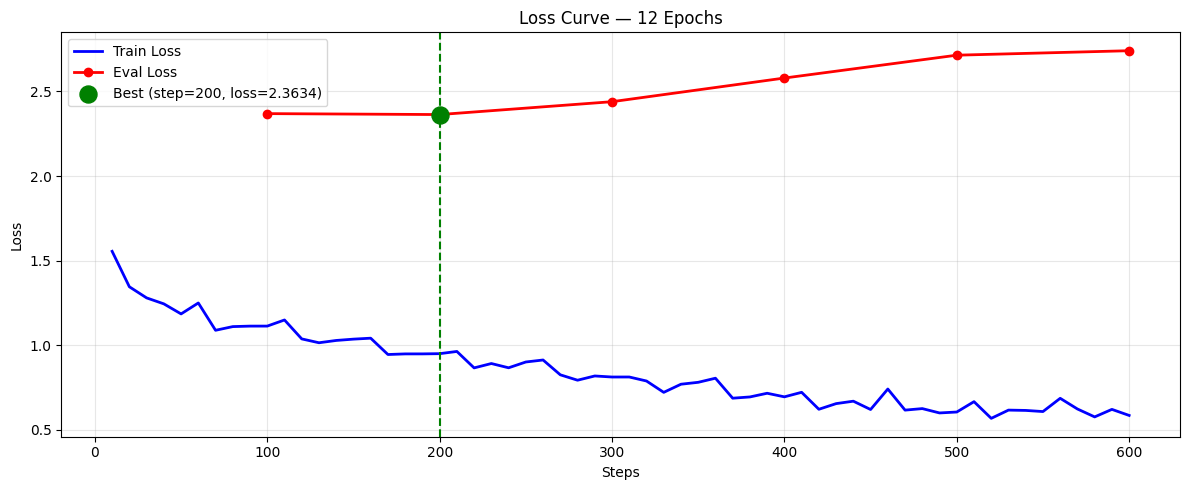

📉 Best eval loss : 2.3634 at step 200
📉 Final train loss: 0.5849
📉 Final eval loss : 2.7408
⚠️  Overfitting! Best checkpoint was at step 200


In [12]:
import matplotlib.pyplot as plt

def plot_loss(logs, title, save_name):
    train_logs = [(x['step'], x['loss']) for x in logs if 'loss' in x and 'eval_loss' not in x]
    eval_logs  = [(x['step'], x['eval_loss']) for x in logs if 'eval_loss' in x]

    train_steps, train_losses = zip(*train_logs)
    eval_steps,  eval_losses  = zip(*eval_logs)

    best_idx  = eval_losses.index(min(eval_losses))
    best_step = eval_steps[best_idx]
    best_loss = eval_losses[best_idx]

    plt.figure(figsize=(12, 5))
    plt.plot(train_steps, train_losses, label='Train Loss', color='blue', linewidth=2)
    plt.plot(eval_steps,  eval_losses,  label='Eval Loss',  color='red',  linewidth=2, marker='o')
    plt.axvline(x=best_step, color='green', linestyle='--')
    plt.scatter([best_step], [best_loss], color='green', s=150, zorder=5,
                label=f'Best (step={best_step}, loss={best_loss:.4f})')
    plt.xlabel('Steps')
    plt.ylabel('Loss')
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/{save_name}.png", dpi=150)
    plt.show()
    print(f"📉 Best eval loss : {best_loss:.4f} at step {best_step}")
    print(f"📉 Final train loss: {train_losses[-1]:.4f}")
    print(f"📉 Final eval loss : {eval_losses[-1]:.4f}")

    # Diagnosis
    if eval_losses[-1] > best_loss * 1.05:
        print("⚠️  Overfitting! Best checkpoint was at step", best_step)
    else:
        print("✅ Still learning — can train more epochs")

# Plot 4 epoch curve
plot_loss(logs_12, "Loss Curve — 12 Epochs", "loss_curve_12epoch")

In [16]:
#Load Best Checkpoint & Save Properly
import os
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

# Find best checkpoint (step 200)
checkpoint_path = "./results/checkpoint-200"
print(f"Using checkpoint: {checkpoint_path}")

# Load fresh base model
base_model = AutoModelForCausalLM.from_pretrained(
    "md-nishat-008/TigerLLM-1B-it",
    torch_dtype=torch.float16,
    device_map="cpu",
    trust_remote_code=True
)

# Attach LoRA from best checkpoint
best_model = PeftModel.from_pretrained(base_model, checkpoint_path)

# Merge LoRA into base
best_model = best_model.merge_and_unload()
print("✅ Best checkpoint merged!")

# Save
best_model.save_pretrained("/kaggle/working/TigerLLM-Medical-Final", safe_serialization=True)
tokenizer.save_pretrained("/kaggle/working/TigerLLM-Medical-Final")
print("✅ Saved!")

Using checkpoint: ./results/checkpoint-200
✅ Best checkpoint merged!
✅ Saved!
